# 11 - Đo RAM, Độ trễ (Latency) và Tối ưu tốc độ (Prompt Cache + N-gram + KV Q8) trên Qwen2.5-0.5B

**Mục tiêu:** Đánh giá các kỹ thuật tối ưu tốc độ suy luận thực tế trên CPU (`ngl=0`, `4 luồng`) cho 2 bản quant tốt nhất từ Notebook 09 (`Q4_K_M-imx` - chính xác nhất, và `IQ4_NL-imx` - nhanh nhất & 0% gọi thừa), đồng thời đo trực tiếp:
1. **RAM thực tế của tiến trình `llama-server`:** `ram_load_mb` (sau khi nạp model) và `ram_peak_mb` (đỉnh RAM trong suốt 156 câu hỏi).
2. **Thời gian trả lời từng câu hỏi (Latency):** Trung bình (`mean_s`), trung vị (`median_s`), P95 (`p95_s`) và thời gian ra token đầu tiên (`ttft_s`).
3. **Độ chính xác Tool Calling (156 ca):** Đảm bảo các kỹ thuật tăng tốc không làm giảm độ chính xác.

### 4 cấu hình tối ưu được đem ra so sánh
1. **`baseline`**: Cấu hình cũ của benchmark (`--cache-ram 0`, `cache_prompt=False`, `--no-repack`, không n-gram).
2. **`cache_prompt`**: Bật `--cache-prompt` (`--cache-ram 128`, `cache_prompt=True`), bỏ `--no-repack` để CPU tự sắp xếp layout SIMD tối ưu.
3. **`cache_ngram_simple`**: Kết hợp `cache_prompt` + `--spec-type ngram-simple --spec-ngram-simple-size-n 4 --spec-ngram-simple-size-m 12`.
4. **`cache_ngram_cache_kv8`**: Kết hợp `cache_prompt` + `--spec-type ngram-cache` + lượng tử hóa KV Cache (`-ctk q8_0 -ctv q8_0`) + Flash Attention (`-fa on`).

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import slm_tools as st
import model_catalog as mc
import tool_cases as T

LLAMA_CPP_DIR = Path("./llama.cpp")
SERVER_BIN = mc.find_llama_bin("llama-server", LLAMA_CPP_DIR)
MODEL_NAME = "Qwen2.5-0.5B-Instruct"
QUANT_DIR = mc.CACHE_DIR / "gguf" / "qwen25_05b_quants"

# Đo trên CPU thuần (ngl=0, 4 luồng) để thấy rõ mức tăng tốc của Prompt Cache & N-gram
# (tương tự hành vi CPU trên thiết bị biên; có thể đổi EVAL_NGL = 99 nếu muốn đo trên GPU).
EVAL_THREADS = 4
EVAL_NGL = 0
N_CTX = 2048

# Các bản quant tốt nhất từ Notebook 09 (+ Q4_K_M gốc để đối chứng)
TARGET_QUANTS = ["Q4_K_M", "Q4_K_M-imx", "IQ4_NL-imx"]

# 4 cấu hình tối ưu tốc độ
OPT_PROFILES = [
    {
        "opt_id": "baseline",
        "label": "Mặc định cũ (no cache, no-repack)",
        "cache_prompt": False,
        "extra_flags": ["--cache-ram", "0", "--no-repack"],
    },
    {
        "opt_id": "cache_prompt",
        "label": "Prompt Cache + Repack",
        "cache_prompt": True,
        "extra_flags": ["--cache-ram", "128"],
    },
    {
        "opt_id": "cache_ngram_simple",
        "label": "Prompt Cache + N-gram Simple",
        "cache_prompt": True,
        "extra_flags": [
            "--cache-ram", "128",
            "--spec-type", "ngram-simple",
            "--spec-ngram-simple-size-n", "4",
            "--spec-ngram-simple-size-m", "12",
        ],
    },
    {
        "opt_id": "cache_ngram_cache_kv8",
        "label": "Prompt Cache + N-gram Cache + KV Q8",
        "cache_prompt": True,
        "extra_flags": [
            "--cache-ram", "128",
            "--spec-type", "ngram-cache",
            "-ctk", "q8_0", "-ctv", "q8_0", "-fa", "on",
        ],
    },
]

for qid in TARGET_QUANTS:
    p = QUANT_DIR / f"{MODEL_NAME}.{qid}.gguf"
    assert p.exists(), f"Thiếu file {p}. Hãy chạy Notebook 09 trước."
print(f"Đã sẵn sàng {len(TARGET_QUANTS)} model x {len(OPT_PROFILES)} cấu hình (EVAL_THREADS={EVAL_THREADS}, EVAL_NGL={EVAL_NGL})")

Đã sẵn sàng 3 model x 4 cấu hình (EVAL_THREADS=4, EVAL_NGL=0)


## Bước 1 - Chạy đo RAM, Latency từng câu hỏi và Tool Calling

Lưu ý: Có thể chạy trên toàn bộ **156 ca** (`MAX_CASES = None`) hoặc đặt `MAX_CASES = 50` nếu bạn muốn test nhanh trước.

In [2]:
MAX_CASES = None  # Đặt số nguyên (vd 50) để test nhanh, hoặc None để chạy đủ 156 ca
CASES = T.make_cases()[:MAX_CASES] if MAX_CASES else T.make_cases()
TOOL_NAMES = T.TOOL_SETS[11]

RESULT_FILE = st.RESULTS_DIR / "qwen25_05b_speed_opt.json"
st.RESULTS_DIR.mkdir(exist_ok=True)

def make_server_cmd(gguf_path: Path, extra_flags: list[str]):
    def _build(port: int):
        return [
            str(SERVER_BIN),
            "-m", str(gguf_path),
            "--host", "127.0.0.1",
            "--port", str(port),
            "-c", str(N_CTX),
            "-t", str(EVAL_THREADS),
            "-ngl", str(EVAL_NGL),
            "-b", "64", "-ub", "64",
            "-np", "1",
            "--jinja",
            *extra_flags,
        ]
    return _build

def run_one_profile(qid: str, profile: dict) -> dict:
    gguf_path = QUANT_DIR / f"{MODEL_NAME}.{qid}.gguf"
    size_mib = round(gguf_path.stat().st_size / (1024 ** 2), 1)
    cfg = {
        "id": f"{MODEL_NAME}__{qid}__{profile['opt_id']}",
        "name": MODEL_NAME,
        "quant": "Q4_K_M",
        "file": gguf_path,
    }

    rows = []
    latencies = []
    ttfts = []
    tokens_list = []

    cmd_builder = make_server_cmd(gguf_path, profile["extra_flags"])
    with st.server(cfg, gpu_layers=EVAL_NGL, command=cmd_builder) as srv:
        ram_load_mb = round(srv.ram.peak_mb, 1)
        for c in CASES:
            msgs, tools = T.native_request(c, TOOL_NAMES)
            out = srv.ask(msgs, tools=tools, max_tokens=150, cache_prompt=profile["cache_prompt"])
            sc = T.score_native(c, out)
            latencies.append(out["total_s"])
            if out["first_token_s"] is not None:
                ttfts.append(out["first_token_s"])
            tokens_list.append(out["tokens"])
            rows.append({
                "want_tool": c["tool"],
                "called": bool(out.get("tool_calls")),
                **sc,
            })
        srv.ram.stop()
        ram_peak_mb = round(srv.ram.peak_mb, 1)

    df = pd.DataFrame(rows)
    in_scope = df[df["want_tool"].notna()]
    oos = df[df["want_tool"].isna()]
    intent_correct = ((in_scope["called"] == True).sum() + (oos["called"] == False).sum()) / len(df)

    # Bỏ câu đầu tiên (cold start) khi tính trung bình ổn định, đồng thời lưu cả full mean
    warm_lat = latencies[1:] if len(latencies) > 1 else latencies
    return {
        "run_id": f"{qid} | {profile['opt_id']}",
        "quant_id": qid,
        "opt_id": profile["opt_id"],
        "opt_label": profile["label"],
        "size_mib": size_mib,
        "ram_load_mb": ram_load_mb,
        "ram_peak_mb": ram_peak_mb,
        "mean_latency_s": round(float(np.mean(warm_lat)), 3),
        "median_latency_s": round(float(np.median(warm_lat)), 3),
        "p95_latency_s": round(float(np.percentile(warm_lat, 95)), 3),
        "mean_ttft_s": round(float(np.mean(ttfts[1:] if len(ttfts) > 1 else ttfts)), 3) if ttfts else None,
        "avg_tokens": round(float(np.mean(tokens_list)), 1),
        "intent_acc": round(float(intent_correct), 4),
        "over_calling": round(float(oos["over_trigger"].mean()), 4),
        "tool_select_acc": round(float(in_scope["ok"].mean()), 4),
        "overall_acc": round(float(df["ok"].mean()), 4),
    }

saved = json.loads(RESULT_FILE.read_text(encoding="utf-8")) if RESULT_FILE.exists() else []
done_map = {r["run_id"]: r for r in saved}

for qid in TARGET_QUANTS:
    for profile in OPT_PROFILES:
        if qid == "Q4_K_M" and profile["opt_id"] != "baseline":
            continue  # Q4_K_M chỉ chạy baseline để làm mốc đối chứng
        rid = f"{qid} | {profile['opt_id']}"
        if rid in done_map:
            r = done_map[rid]
            print(f"[đã đo] {rid}: {r['mean_latency_s']}s/câu | RAM peak={r['ram_peak_mb']} MB | Acc={r['overall_acc']*100:.1f}%")
            continue
        print(f"\n=== Đang đo {rid} ({len(CASES)} ca, ngl={EVAL_NGL}, t={EVAL_THREADS}) ===")
        t0 = time.perf_counter()
        rec = run_one_profile(qid, profile)
        done_map[rid] = rec
        RESULT_FILE.write_text(json.dumps(list(done_map.values()), indent=2, ensure_ascii=False), encoding="utf-8")
        print(
            f"  -> Latency TB = {rec['mean_latency_s']:.2f}s (P95 = {rec['p95_latency_s']:.2f}s, TTFT = {rec['mean_ttft_s']}s) | "
            f"RAM = {rec['ram_peak_mb']} MB | Tool = {rec['tool_select_acc']*100:.1f}% | "
            f"Tổng hợp = {rec['overall_acc']*100:.1f}% (xong sau {time.perf_counter() - t0:.0f}s)"
        )


=== Đang đo Q4_K_M | baseline (156 ca, ngl=0, t=4) ===
  -> Latency TB = 3.17s (P95 = 3.50s, TTFT = 2.858s) | RAM = 507.9 MB | Tool = 44.7% | Tổng hợp = 46.8% (xong sau 495s)

=== Đang đo Q4_K_M-imx | baseline (156 ca, ngl=0, t=4) ===
  -> Latency TB = 3.24s (P95 = 3.65s, TTFT = 2.899s) | RAM = 507.3 MB | Tool = 47.0% | Tổng hợp = 53.2% (xong sau 507s)

=== Đang đo Q4_K_M-imx | cache_prompt (156 ca, ngl=0, t=4) ===
  -> Latency TB = 0.54s (P95 = 0.96s, TTFT = 0.198s) | RAM = 572.7 MB | Tool = 46.2% | Tổng hợp = 53.8% (xong sau 86s)

=== Đang đo Q4_K_M-imx | cache_ngram_simple (156 ca, ngl=0, t=4) ===
  -> Latency TB = 0.69s (P95 = 1.06s, TTFT = 0.302s) | RAM = 583.2 MB | Tool = 45.5% | Tổng hợp = 53.2% (xong sau 111s)

=== Đang đo Q4_K_M-imx | cache_ngram_cache_kv8 (156 ca, ngl=0, t=4) ===
  -> Latency TB = 0.84s (P95 = 1.39s, TTFT = 0.3s) | RAM = 552.3 MB | Tool = 39.4% | Tổng hợp = 48.7% (xong sau 136s)

=== Đang đo IQ4_NL-imx | baseline (156 ca, ngl=0, t=4) ===
  -> Latency TB = 3.

## Bước 2 - Bảng tổng hợp & Biểu đồ so sánh (RAM, Thời gian trả lời, Độ chính xác)

,Cấu hình,File (MiB),RAM nạp (MB),RAM đỉnh (MB),Trả lời TB (s),P95 (s),TTFT TB (s),Intent,Gọi thừa,Chọn đúng tool,Tổng hợp
0,Q4_K_M | baseline,379.4,468,508,3.17s (1.00x),3.50s,2.86s,57.7%,41.7%,44.7%,46.8%
1,Q4_K_M-imx | baseline,379.4,467,507,3.24s (0.98x),3.65s,2.90s,63.5%,12.5%,47.0%,53.2%
2,Q4_K_M-imx | cache_prompt,379.4,495,573,0.54s (5.93x),0.96s,0.20s,63.5%,4.2%,46.2%,53.8%
3,Q4_K_M-imx | cache_ngram_simple,379.4,495,583,0.69s (4.58x),1.06s,0.30s,63.5%,4.2%,45.5%,53.2%
4,Q4_K_M-imx | cache_ngram_cache_kv8,379.4,484,552,0.84s (3.77x),1.39s,0.30s,66.7%,0.0%,39.4%,48.7%
5,IQ4_NL-imx | baseline,336.3,424,462,3.05s (1.04x),3.42s,2.74s,54.5%,0.0%,34.8%,44.9%
6,IQ4_NL-imx | cache_prompt,336.3,615,691,0.45s (7.06x),0.76s,0.17s,55.8%,0.0%,35.6%,45.5%
7,IQ4_NL-imx | cache_ngram_simple,336.3,615,702,0.56s (5.70x),0.86s,0.23s,55.8%,0.0%,34.8%,44.9%
8,IQ4_NL-imx | cache_ngram_cache_kv8,336.3,604,670,0.68s (4.68x),1.18s,0.26s,57.7%,0.0%,37.9%,47.4%


Đã lưu biểu đồ tại: charts\11_qwen25_05b_speed_opt_comparison.png


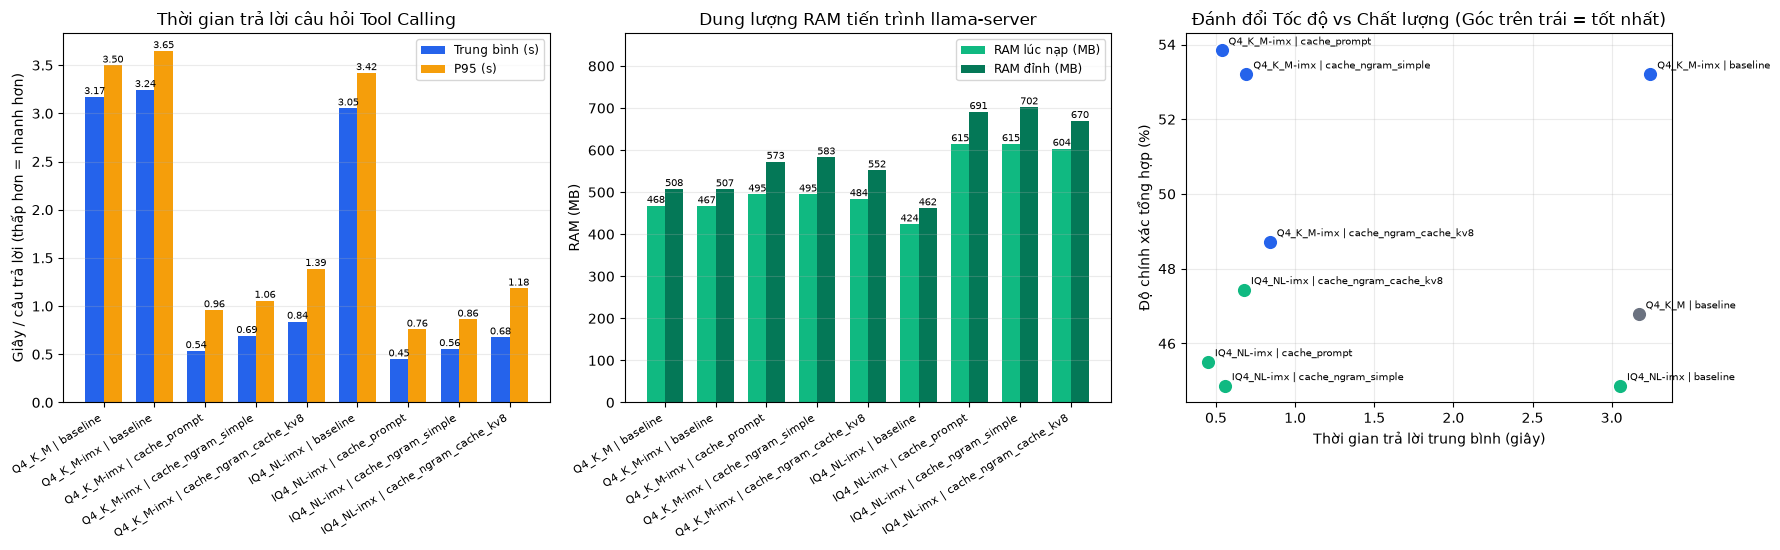

In [3]:
records = json.loads(RESULT_FILE.read_text(encoding="utf-8"))
df_opt = pd.DataFrame(records)

# Tính tốc độ nhanh hơn bao nhiêu lần so với Q4_K_M | baseline
base_lat = df_opt[df_opt["run_id"] == "Q4_K_M | baseline"]["mean_latency_s"].iloc[0]

disp = pd.DataFrame({
    "Cấu hình": df_opt["run_id"],
    "File (MiB)": df_opt["size_mib"].map(lambda v: f"{v:.1f}"),
    "RAM nạp (MB)": df_opt["ram_load_mb"].map(lambda v: f"{v:.0f}"),
    "RAM đỉnh (MB)": df_opt["ram_peak_mb"].map(lambda v: f"{v:.0f}"),
    "Trả lời TB (s)": df_opt["mean_latency_s"].map(lambda v: f"{v:.2f}s ({base_lat/v:.2f}x)"),
    "P95 (s)": df_opt["p95_latency_s"].map(lambda v: f"{v:.2f}s"),
    "TTFT TB (s)": df_opt["mean_ttft_s"].map(lambda v: f"{v:.2f}s" if pd.notna(v) else "-"),
    "Intent": df_opt["intent_acc"].map(lambda v: f"{v*100:.1f}%"),
    "Gọi thừa": df_opt["over_calling"].map(lambda v: f"{v*100:.1f}%"),
    "Chọn đúng tool": df_opt["tool_select_acc"].map(lambda v: f"{v*100:.1f}%"),
    "Tổng hợp": df_opt["overall_acc"].map(lambda v: f"{v*100:.1f}%"),
})
display(disp)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
x = np.arange(len(df_opt))
labels = df_opt["run_id"].tolist()

# Biểu đồ 1: Thời gian trả lời câu hỏi (giây)
ax1 = axes[0]
w = 0.36
b1 = ax1.bar(x - w/2, df_opt["mean_latency_s"], w, label="Trung bình (s)", color="#2563eb")
b2 = ax1.bar(x + w/2, df_opt["p95_latency_s"],  w, label="P95 (s)",        color="#f59e0b")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=32, ha="right", fontsize=8)
ax1.set_ylabel("Giây / câu trả lời (thấp hơn = nhanh hơn)")
ax1.set_title("Thời gian trả lời câu hỏi Tool Calling")
ax1.legend(loc="upper right", fontsize=8.5)
ax1.grid(axis="y", alpha=0.25)
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f"{h:.2f}", (bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7)

# Biểu đồ 2: RAM sử dụng thực tế (MB)
ax2 = axes[1]
r1 = ax2.bar(x - w/2, df_opt["ram_load_mb"], w, label="RAM lúc nạp (MB)", color="#10b981")
r2 = ax2.bar(x + w/2, df_opt["ram_peak_mb"], w, label="RAM đỉnh (MB)",    color="#047857")
ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=32, ha="right", fontsize=8)
ax2.set_ylim(0, max(df_opt["ram_peak_mb"].max() * 1.25, 600))
ax2.set_ylabel("RAM (MB)")
ax2.set_title("Dung lượng RAM tiến trình llama-server")
ax2.legend(loc="upper right", fontsize=8.5)
ax2.grid(axis="y", alpha=0.25)
for bars in (r1, r2):
    for bar in bars:
        h = bar.get_height()
        ax2.annotate(f"{h:.0f}", (bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7)

# Biểu đồ 3: Đánh đổi Thời gian trả lời vs Độ chính xác tổng hợp
ax3 = axes[2]
q_colors = {"Q4_K_M": "#6b7280", "Q4_K_M-imx": "#2563eb", "IQ4_NL-imx": "#10b981"}
for _, r in df_opt.iterrows():
    ax3.scatter(r["mean_latency_s"], r["overall_acc"] * 100, s=110,
                color=q_colors.get(r["quant_id"], "#333"), edgecolor="white", zorder=3)
    ax3.annotate(r["run_id"], (r["mean_latency_s"], r["overall_acc"] * 100),
                 xytext=(5, 4), textcoords="offset points", fontsize=7.5)
ax3.set_xlabel("Thời gian trả lời trung bình (giây)")
ax3.set_ylabel("Độ chính xác tổng hợp (%)")
ax3.set_title("Đánh đổi Tốc độ vs Chất lượng (Góc trên trái = tốt nhất)")
ax3.grid(alpha=0.25)

fig.tight_layout()
st.CHARTS_DIR.mkdir(exist_ok=True)
chart_path = st.CHARTS_DIR / "11_qwen25_05b_speed_opt_comparison.png"
fig.savefig(chart_path, dpi=180, bbox_inches="tight")
print("Đã lưu biểu đồ tại:", chart_path)
plt.show()